# TP4 – UC-08 : Analyse des données et visualisation (scripts HDFS, fichier complet)

**Projet** : Retail Intelligence Platform (IPSSI) – **Groupe** : Noah, Lorenzo – **Auteur du notebook** : Noah

**Objectifs de l'analyse**

- Reprendre les données Silver et Gold produites au TP3 (scripts PySpark sur HDFS).
- Calculer les KPI du dictionnaire du Jour 1 qui sont calculables avec ces données.
- Produire des statistiques descriptives.
- Répondre à deux questions métier, avec un graphique pour chacune.
- Interpréter les résultats sans dire plus que ce que les données permettent.

**Méthode** : Spark fait les calculs et les agrégations. Seuls les petits tableaux de résultats passent dans Pandas, pour faire les graphiques avec Matplotlib.

> Les données TPCx-BB sont **synthétiques** (générées au hasard). Les résultats servent à travailler la démarche, ce ne sont pas des observations d'une vraie entreprise.

## 1. Import des bibliothèques

In [1]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import pyspark
from pyspark.sql import SparkSession, functions as F

print("Python     :", sys.version.split()[0])
print("PySpark    :", pyspark.__version__)
print("Pandas     :", pd.__version__)
print("Matplotlib :", matplotlib.__version__)

Python     : 3.12.3
PySpark    : 4.3.0
Pandas     : 3.1.1
Matplotlib : 3.11.2


**Paramètres** : les chemins des données (HDFS du Jour 2) et des sorties sont regroupés ici.
Les sorties sont écrites dans `analytics/outputs/hdfs/` (tableaux CSV) et `analytics/visualizations/hdfs/` (graphiques PNG), à côté de celles du notebook principal `TP4_Retail_Intelligence.ipynb` (échantillon de 10 %).

In [2]:
HDFS = "hdfs://localhost:9000"
LAKE = HDFS + "/retail-lake"

SILVER_VENTES = LAKE + "/silver/store_sales"
SILVER_PRODUITS = LAKE + "/silver/item"
GOLD_CA_CATEGORIE = LAKE + "/gold/ca_par_categorie"

# Le notebook est dans analytics/notebooks/ : les sorties vont dans les dossiers voisins
DOSSIER_SORTIES = Path("../outputs/hdfs")
DOSSIER_GRAPHIQUES = Path("../visualizations/hdfs")
DOSSIER_SORTIES.mkdir(parents=True, exist_ok=True)
DOSSIER_GRAPHIQUES.mkdir(parents=True, exist_ok=True)

SOURCE_DONNEES = "Source : TPCx-BB (données synthétiques), Data Lake HDFS du projet"

## 2. Création de la session Spark

Mêmes réglages qu'au TP3 : mode `local[*]`, 2 Go de mémoire, et 1 seule copie dans HDFS (notre HDFS n'a qu'un DataNode).

In [3]:
spark = (
    SparkSession.builder
    .appName("TP4-Retail-Intelligence")
    .master("local[*]")
    .config("spark.driver.memory", "2g")
    .config("spark.hadoop.dfs.replication", "1")
    .config("spark.ui.showConsoleProgress", "false")             # pas de barres de progression dans les sorties
    .config("spark.sql.execution.arrow.pyspark.enabled", "false")  # pyarrow n'est pas installé
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print("Version Spark :", spark.version)
print("Mode          :", spark.sparkContext.master)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/19 17:13:43 WARN Utils: Your hostname, DESKTOP-DCTNJ6T, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/19 17:13:43 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/noah/retail-intelligence/tp3/.venv/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/19 17:13:44 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Version Spark : 4.3.0
Mode          : local[*]


## 3. Chargement des jeux de données

Trois jeux produits au TP3 par les scripts `01_silver.py` et `02_gold.py`, tous en Parquet dans HDFS :

- `silver/store_sales` : les ventes en magasin nettoyées ;
- `silver/item` : les produits nettoyés ;
- `gold/ca_par_categorie` : la synthèse des ventes par catégorie.

In [4]:
ventes = spark.read.parquet(SILVER_VENTES)
produits = spark.read.parquet(SILVER_PRODUITS)
gold_categorie = spark.read.parquet(GOLD_CA_CATEGORIE)

ventes.cache()
for nom, df in [("silver/store_sales", ventes), ("silver/item", produits), ("gold/ca_par_categorie", gold_categorie)]:
    print(f"{nom:24} {df.count():>9} lignes  {len(df.columns):>3} colonnes")

silver/store_sales          667579 lignes   27 colonnes


silver/item                  17820 lignes   24 colonnes


gold/ca_par_categorie            9 lignes    8 colonnes


## 4. Vérification des schémas, des volumes et de la granularité

In [5]:
ventes.printSchema()

root
 |-- ss_sold_date_sk: integer (nullable = true)
 |-- ss_sold_time_sk: integer (nullable = true)
 |-- ss_item_sk: integer (nullable = true)
 |-- ss_customer_sk: integer (nullable = true)
 |-- ss_cdemo_sk: integer (nullable = true)
 |-- ss_hdemo_sk: integer (nullable = true)
 |-- ss_addr_sk: integer (nullable = true)
 |-- ss_store_sk: integer (nullable = true)
 |-- ss_promo_sk: integer (nullable = true)
 |-- ss_ticket_number: integer (nullable = true)
 |-- ss_quantity: integer (nullable = true)
 |-- ss_wholesale_cost: decimal(7,2) (nullable = true)
 |-- ss_list_price: decimal(7,2) (nullable = true)
 |-- ss_sales_price: decimal(7,2) (nullable = true)
 |-- ss_ext_discount_amt: decimal(7,2) (nullable = true)
 |-- ss_ext_sales_price: decimal(7,2) (nullable = true)
 |-- ss_ext_wholesale_cost: decimal(7,2) (nullable = true)
 |-- ss_ext_list_price: decimal(7,2) (nullable = true)
 |-- ss_ext_tax: decimal(7,2) (nullable = true)
 |-- ss_coupon_amt: decimal(7,2) (nullable = true)
 |-- ss_net_p

In [6]:
produits.select("i_item_sk", "i_item_id", "i_category", "i_class", "i_current_price").printSchema()
gold_categorie.printSchema()

root
 |-- i_item_sk: integer (nullable = true)
 |-- i_item_id: string (nullable = true)
 |-- i_category: string (nullable = true)
 |-- i_class: string (nullable = true)
 |-- i_current_price: decimal(7,2) (nullable = true)

root
 |-- categorie: string (nullable = true)
 |-- chiffre_affaires: decimal(17,2) (nullable = true)
 |-- quantite_vendue: long (nullable = true)
 |-- nombre_lignes_vente: long (nullable = true)
 |-- nombre_produits_vendus: long (nullable = true)
 |-- part_ca_pct: decimal(5,2) (nullable = true)
 |-- source: string (nullable = true)
 |-- date_traitement: timestamp (nullable = true)



In [7]:
ventes.select("ss_ticket_number", "ss_store_sk", "ss_item_sk", "ss_quantity",
              "ss_sales_price", "ss_ext_list_price", "ss_ext_discount_amt", "ss_net_paid").show(5)

+----------------+-----------+----------+-----------+--------------+-----------------+-------------------+-----------+
|ss_ticket_number|ss_store_sk|ss_item_sk|ss_quantity|ss_sales_price|ss_ext_list_price|ss_ext_discount_amt|ss_net_paid|
+----------------+-----------+----------+-----------+--------------+-----------------+-------------------+-----------+
|              20|          7|      7073|         41|          4.64|           703.97|             513.73|     190.24|
|              36|          1|     10003|         29|         37.63|          1704.91|             613.64|    1091.27|
|              36|          1|     13725|         60|         17.82|          1876.20|             807.00|     748.44|
|              12|          2|      6655|         20|         32.77|          1170.40|             515.00|     655.40|
|              12|          2|      6719|         27|         43.60|          2942.73|            1765.53|     800.50|
+----------------+-----------+----------+-------

**Granularité** : on vérifie ce que représente une ligne avant de compter quoi que ce soit.

- Une ligne de `store_sales` est-elle un ticket, ou une ligne de ticket ?
- Un ticket appartient-il à un seul magasin ? (sinon, le nombre de tickets par magasin serait faux)
- La clé `ss_item_sk` → `i_item_sk` est-elle sûre ? (vérifiée au TP3, on la recontrôle)

In [8]:
nb_lignes = ventes.count()
nb_tickets = ventes.select("ss_ticket_number").distinct().count()
nb_couples_ticket_magasin = ventes.select("ss_ticket_number", "ss_store_sk").distinct().count()
nb_couples_ticket_produit = ventes.select("ss_ticket_number", "ss_item_sk").distinct().count()

print("Lignes de vente                       :", nb_lignes)
print("Tickets différents                    :", nb_tickets)
print("Lignes par ticket en moyenne          :", round(nb_lignes / nb_tickets, 2))
print("Couples (ticket, magasin) différents  :", nb_couples_ticket_magasin)
print("  -> un ticket = un seul magasin      :", nb_couples_ticket_magasin == nb_tickets)
print("Couples (ticket, produit) différents  :", nb_couples_ticket_produit)

nb_produits = produits.count()
nb_ids_produits = produits.select("i_item_sk").distinct().count()
ventes_sans_produit = ventes.join(produits, ventes.ss_item_sk == produits.i_item_sk, "left_anti").count()
print("i_item_sk unique dans item            :", nb_produits == nb_ids_produits, f"({nb_ids_produits} pour {nb_produits})")
print("Ventes dont le produit est inconnu    :", ventes_sans_produit)
print("Magasins différents (ss_store_sk)     :", ventes.select("ss_store_sk").distinct().count())
print("Catégories dans le Gold               :", gold_categorie.count())

Lignes de vente                       : 667579
Tickets différents                    : 89100
Lignes par ticket en moyenne          : 7.49
Couples (ticket, magasin) différents  : 89100
  -> un ticket = un seul magasin      : True
Couples (ticket, produit) différents  : 663443


i_item_sk unique dans item            : True (17820 pour 17820)
Ventes dont le produit est inconnu    : 0


Magasins différents (ss_store_sk)     : 12
Catégories dans le Gold               : 9


## 5. Calcul des KPI

KPI du dictionnaire du Jour 1 (`01_UC01_besoin_exploration/UC01_dictionnaire_KPI.md`), **pour les ventes en magasin seulement** (`web_sales` n'est pas dans notre Silver) :

| KPI | Formule | Champs |
|---|---|---|
| KPI-01 Chiffre d'affaires | somme de `ss_net_paid` | `ss_net_paid` |
| KPI-02 Nombre de transactions | nombre de `ss_ticket_number` différents | `ss_ticket_number` |
| KPI-03 Panier moyen | KPI-01 ÷ KPI-02 | `ss_net_paid`, `ss_ticket_number` |
| KPI-04 Quantités vendues | somme de `ss_quantity` | `ss_quantity` |
| KPI-05 Taux de remise | somme de `ss_ext_discount_amt` ÷ somme de `ss_ext_list_price` × 100 | `ss_ext_discount_amt`, `ss_ext_list_price` |

Non calculés : **KPI-06** (évolution du CA) car `date_dim` n'est pas dans notre Silver, et la **marge**, car 74 % des lignes ont une marge négative (TP3, étape 3).

In [9]:
kpi = ventes.agg(
    F.sum("ss_net_paid").alias("ca"),
    F.countDistinct("ss_ticket_number").alias("transactions"),
    F.sum("ss_quantity").alias("quantites"),
    F.sum("ss_ext_discount_amt").alias("remises"),
    F.sum("ss_ext_list_price").alias("prix_catalogue"),
    F.count("*").alias("lignes"),
).first()

ca = float(kpi["ca"])
transactions = kpi["transactions"]
tableau_kpi = pd.DataFrame([
    ["KPI-01", "Chiffre d'affaires", round(ca, 2), "euros (supposé)"],
    ["KPI-02", "Nombre de transactions", transactions, "tickets"],
    ["KPI-03", "Panier moyen", round(ca / transactions, 2), "euros par ticket"],
    ["KPI-04", "Quantités vendues", kpi["quantites"], "articles"],
    ["KPI-05", "Taux de remise", round(float(kpi["remises"]) / float(kpi["prix_catalogue"]) * 100, 2), "%"],
], columns=["code", "kpi", "valeur", "unite"], dtype=object)
tableau_kpi["perimetre"] = "ventes en magasin, toute la période, fichier complet"
tableau_kpi["source"] = "silver/store_sales"

tableau_kpi.to_csv(DOSSIER_SORTIES / "kpi.csv", index=False)
print("Pour comparer : nombre de lignes de vente =", kpi["lignes"], "(ce n'est PAS le nombre de transactions)")
tableau_kpi

Pour comparer : nombre de lignes de vente = 667579 (ce n'est PAS le nombre de transactions)


,code,kpi,valeur,unite,perimetre,source
0,KPI-01,Chiffre d'affaires,1150529586.37,euros (supposé),"ventes en magasin, toute la période, fichier c...",silver/store_sales
1,KPI-02,Nombre de transactions,89100,tickets,"ventes en magasin, toute la période, fichier c...",silver/store_sales
2,KPI-03,Panier moyen,12912.79,euros par ticket,"ventes en magasin, toute la période, fichier c...",silver/store_sales
3,KPI-04,Quantités vendues,33755474,articles,"ventes en magasin, toute la période, fichier c...",silver/store_sales
4,KPI-05,Taux de remise,49.99,%,"ventes en magasin, toute la période, fichier c...",silver/store_sales


**Contrôle** : le CA calculé ici doit être égal à la somme du CA du Gold (même source, même règle).

In [10]:
ca_gold = float(gold_categorie.agg(F.sum("chiffre_affaires")).first()[0])
print("CA Silver :", round(ca, 2), "| CA Gold :", round(ca_gold, 2), "| écart :", round(ca - ca_gold, 2))

CA Silver : 1150529586.37 | CA Gold : 1150529586.37 | écart : 0.0


## 6. Statistiques descriptives

Sur `silver/store_sales`, pour les mesures numériques (les colonnes `_sk` sont des identifiants : on ne calcule pas de moyenne dessus).
On ajoute le **montant par ticket**, calculé d'abord par Spark (une ligne par ticket), pour voir la distribution des paniers.

In [11]:
def statistiques(df, colonne, libelle, niveau):
    s = df.agg(
        F.count(colonne).alias("nombre"),
        F.min(colonne).alias("minimum"),
        F.max(colonne).alias("maximum"),
        F.avg(colonne).alias("moyenne"),
        F.median(colonne).alias("mediane"),
        F.sum(colonne).alias("somme"),
    ).first()
    return {"mesure": libelle, "niveau": niveau,
            **{k: round(float(s[k]), 2) for k in ["nombre", "minimum", "maximum", "moyenne", "mediane", "somme"]}}


montant_par_ticket = ventes.groupBy("ss_ticket_number").agg(
    F.sum("ss_net_paid").alias("montant_ticket"),
    F.count("*").alias("lignes_ticket"),
)

tableau_stats = pd.DataFrame([
    statistiques(ventes, "ss_quantity", "Quantité par ligne (ss_quantity)", "ligne de ticket"),
    statistiques(ventes, "ss_sales_price", "Prix de vente unitaire (ss_sales_price)", "ligne de ticket"),
    statistiques(ventes, "ss_net_paid", "Montant payé par ligne (ss_net_paid)", "ligne de ticket"),
    statistiques(montant_par_ticket, "montant_ticket", "Montant par ticket", "ticket"),
    statistiques(montant_par_ticket, "lignes_ticket", "Lignes par ticket", "ticket"),
])
# La somme n'a de sens que pour les mesures additives
tableau_stats.loc[tableau_stats["mesure"].isin(["Prix de vente unitaire (ss_sales_price)", "Lignes par ticket"]), "somme"] = None
tableau_stats.to_csv(DOSSIER_SORTIES / "statistiques.csv", index=False)
pd.set_option("display.float_format", "{:,.2f}".format)
tableau_stats

,mesure,niveau,nombre,minimum,maximum,moyenne,mediane,somme
0,Quantité par ligne (ss_quantity),ligne de ticket,"667,579.00",1.00,100.00,50.56,51.00,"33,755,474.00"
1,Prix de vente unitaire (ss_sales_price),ligne de ticket,"667,579.00",0.00,199.30,37.86,27.69,NaN
2,Montant payé par ligne (ss_net_paid),ligne de ticket,"667,579.00",0.00,"18,745.00","1,723.44",878.54,"1,150,529,586.37"
3,Montant par ticket,ticket,"89,100.00",0.00,"64,785.95","12,912.79","11,645.15","1,150,529,586.37"
4,Lignes par ticket,ticket,"89,100.00",1.00,14.00,7.49,7.00,NaN


**Répartition par dimension** : nombre de lignes et de tickets par magasin, et étendue de la colonne de jour.

In [12]:
ventes.groupBy("ss_store_sk").agg(
    F.count("*").alias("lignes"),
    F.countDistinct("ss_ticket_number").alias("tickets"),
).orderBy("ss_store_sk").show(12)

ventes.agg(F.min("ss_sold_date_sk").alias("premier_jour_sk"),
           F.max("ss_sold_date_sk").alias("dernier_jour_sk"),
           F.countDistinct("ss_sold_date_sk").alias("jours_differents")).show()

+-----------+------+-------+
|ss_store_sk|lignes|tickets|
+-----------+------+-------+
|          0| 56018|   7456|
|          1| 55676|   7422|
|          2| 54633|   7359|
|          3| 55397|   7396|
|          4| 56211|   7462|
|          5| 55122|   7369|
|          6| 54574|   7284|
|          7| 57589|   7645|
|          8| 55737|   7414|
|          9| 56040|   7435|
|         10| 55109|   7409|
|         11| 55473|   7449|
+-----------+------+-------+



+---------------+---------------+----------------+
|premier_jour_sk|dernier_jour_sk|jours_differents|
+---------------+---------------+----------------+
|          36890|          38697|            1808|
+---------------+---------------+----------------+



`ss_sold_date_sk` est un **numéro de jour**, pas une date. Sans la table `date_dim`, on ne peut pas savoir à quel mois correspond chaque numéro :
**l'évolution dans le temps n'est pas calculable** avec notre Silver (voir les limites).

## 7. Première analyse métier : quelles catégories génèrent le plus de chiffre d'affaires ?

- **Question** (Jour 1, P4 Direction commerciale, Indispensable) : *« Quels produits et quelles catégories génèrent le plus de chiffre d'affaires ? »*
- **Données** : `gold/ca_par_categorie` (CA, quantités, part du CA) et `silver/item` (nombre de produits au catalogue par catégorie).
- **Méthode** : on lit le Gold tel quel (9 lignes). On ajoute la part de chaque catégorie dans le catalogue, pour voir si le CA suit simplement le nombre de produits.

In [13]:
produits_par_categorie = (
    produits.groupBy(F.col("i_category").alias("categorie"))
    .agg(F.count("*").alias("produits_catalogue"))
    .withColumn("part_produits_pct", F.round(F.col("produits_catalogue") / F.lit(nb_produits) * 100, 2))
)

analyse_categories = (
    gold_categorie
    .join(produits_par_categorie, "categorie", "left")
    .withColumn("ca_par_produit", F.round(F.col("chiffre_affaires") / F.col("produits_catalogue"), 2))
    .select("categorie", "chiffre_affaires", "part_ca_pct", "quantite_vendue",
            "produits_catalogue", "part_produits_pct", "ca_par_produit")
    .orderBy(F.desc("chiffre_affaires"))
)

pdf_categories = analyse_categories.toPandas()  # 9 lignes : le transfert vers Pandas est sans risque
pdf_categories["chiffre_affaires"] = pdf_categories["chiffre_affaires"].astype(float)
pdf_categories["part_ca_pct"] = pdf_categories["part_ca_pct"].astype(float)
pdf_categories.to_csv(DOSSIER_SORTIES / "ca_par_categorie.csv", index=False)
pdf_categories

/home/noah/retail-intelligence/tp3/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,categorie,chiffre_affaires,part_ca_pct,quantite_vendue,produits_catalogue,part_produits_pct,ca_par_produit
0,Music,"519,666,693.84",45.17,15238374,8143,45.70,63817.60
1,Books,"307,151,503.25",26.70,9007511,5335,29.94,57572.92
2,Movies & TV,"74,735,891.89",6.50,2189279,1286,7.22,58115.00
3,Clothing & Accessories,"56,754,855.82",4.93,1640550,610,3.42,93040.75
4,Electronics,"55,715,087.49",4.84,1632098,692,3.88,80513.13
5,Home & Kitchen,"41,260,511.11",3.59,1226839,476,2.67,86681.75
6,Sports & Outdoors,"40,926,938.33",3.56,1209305,465,2.61,88014.92
7,Toys & Games,"27,437,825.33",2.38,809999,405,2.27,67747.72
8,Tools & Home Improvement,"26,880,279.31",2.34,801519,408,2.29,65883.04


### Première visualisation : chiffre d'affaires par catégorie

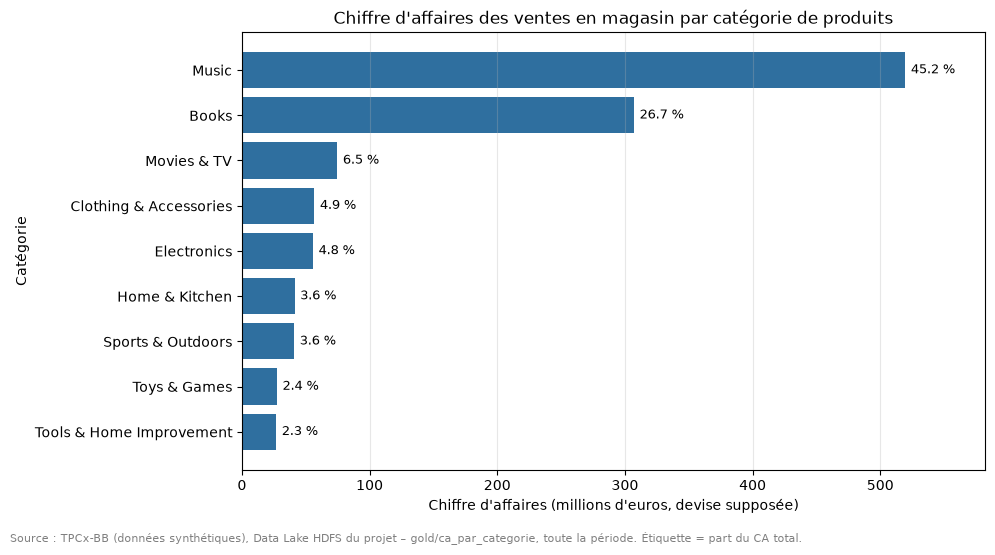

In [14]:
pdf_graph = pdf_categories.sort_values("chiffre_affaires")  # barres horizontales : la plus grande en haut

fig, ax = plt.subplots(figsize=(10, 5.5))
barres = ax.barh(pdf_graph["categorie"], pdf_graph["chiffre_affaires"] / 1e6, color="#2f6f9f")
ax.bar_label(barres, labels=[f"{p:.1f} %" for p in pdf_graph["part_ca_pct"]], padding=4, fontsize=9)

ax.set_title("Chiffre d'affaires des ventes en magasin par catégorie de produits")
ax.set_xlabel("Chiffre d'affaires (millions d'euros, devise supposée)")
ax.set_ylabel("Catégorie")
ax.set_xlim(0, pdf_graph["chiffre_affaires"].max() / 1e6 * 1.12)
ax.grid(axis="x", alpha=0.3)
fig.text(0.01, 0.005, SOURCE_DONNEES + " – gold/ca_par_categorie, toute la période. Étiquette = part du CA total.",
         fontsize=8, color="gray")

fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(DOSSIER_GRAPHIQUES / "ca_par_categorie.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation**

- **Ce que montre le graphique** : le chiffre d'affaires des ventes en magasin de chaque catégorie, sur toute la période.
- **Résultat principal** : `Music` (45,2 %) et `Books` (26,7 %) font à elles deux **71,9 %** du CA. Les 7 autres catégories font chacune entre 2,3 % et 6,5 %.
- **Interprétation possible** : le CA suit surtout le **nombre de produits au catalogue**. `Music` a 45,7 % des produits et 45,2 % du CA, `Books` 29,9 % des produits et 26,7 % du CA. Rapporté au nombre de produits, `Music` fait même moins (63 818 € par produit) que `Clothing & Accessories` (93 041 € par produit). `Music` ne vend donc pas « mieux » : elle a surtout plus de produits.
- **Limites** : données synthétiques ; ventes en magasin seulement ; retours non déduits ; pas de découpage par période ; devise supposée.

## 8. Deuxième analyse métier : quelles différences observe-t-on entre les magasins ?

- **Question** : *« Quelles différences observe-t-on entre les magasins ? »* (exemple du TP). Elle prolonge deux questions du Jour 1 :
  P2 *« Quel est le niveau moyen des remises ? »* et P2 *« Quelle marge fait chaque magasin ? »* (on remplace la marge, pas fiable, par le CA).
- **Données** : `silver/store_sales` (fichier complet). Le magasin est identifié par `ss_store_sk` (12 valeurs, de 0 à 11).
- **Méthode** : regroupement par magasin avec Spark, puis calcul de KPI-01 à KPI-05 pour chaque magasin. Le résultat fait 12 lignes.

In [15]:
kpi_par_magasin = (
    ventes.groupBy(F.col("ss_store_sk").alias("magasin"))
    .agg(
        F.sum("ss_net_paid").alias("chiffre_affaires"),
        F.countDistinct("ss_ticket_number").alias("transactions"),
        F.sum("ss_quantity").alias("quantites_vendues"),
        F.sum("ss_ext_discount_amt").alias("remises"),
        F.sum("ss_ext_list_price").alias("prix_catalogue"),
    )
    .withColumn("panier_moyen", F.round(F.col("chiffre_affaires") / F.col("transactions"), 2))
    .withColumn("taux_remise_pct", F.round(F.col("remises") / F.col("prix_catalogue") * 100, 2))
    .withColumn("part_ca_pct", F.round(F.col("chiffre_affaires") / F.lit(ca) * 100, 2))
    .drop("remises", "prix_catalogue")
    .orderBy(F.desc("chiffre_affaires"))
)

pdf_magasins = kpi_par_magasin.toPandas()  # 12 lignes
for colonne in ["chiffre_affaires", "panier_moyen", "taux_remise_pct", "part_ca_pct"]:
    pdf_magasins[colonne] = pdf_magasins[colonne].astype(float)
pdf_magasins.to_csv(DOSSIER_SORTIES / "kpi_par_magasin.csv", index=False)

print("Contrôle : somme du CA des magasins =", round(pdf_magasins["chiffre_affaires"].sum(), 2), "| CA total =", round(ca, 2))
print("Contrôle : somme des tickets des magasins =", pdf_magasins["transactions"].sum(), "| tickets =", transactions)
print("Écart max / min du CA :", round(pdf_magasins["chiffre_affaires"].max() / pdf_magasins["chiffre_affaires"].min(), 3))
pdf_magasins

/home/noah/retail-intelligence/tp3/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Contrôle : somme du CA des magasins = 1150529586.37 | CA total = 1150529586.37
Contrôle : somme des tickets des magasins = 89100 | tickets = 89100
Écart max / min du CA : 1.052


,magasin,chiffre_affaires,transactions,quantites_vendues,panier_moyen,taux_remise_pct,part_ca_pct
0,7,"98,950,137.76",7645,2915053,"12,943.12",50.13,8.60
1,4,"96,770,105.59",7462,2832572,"12,968.39",50.00,8.41
2,9,"96,748,356.68",7435,2830684,"13,012.56",49.87,8.41
3,0,"96,727,851.94",7456,2830581,"12,973.16",49.91,8.41
4,8,"96,578,622.89",7414,2821869,"13,026.52",49.76,8.39
5,3,"96,063,990.59",7396,2800824,"12,988.64",49.94,8.35
6,1,"95,929,844.66",7422,2817524,"12,925.07",50.08,8.34
7,11,"95,607,843.48",7449,2790631,"12,834.99",49.97,8.31
8,6,"94,751,173.08",7284,2780253,"13,008.12",49.87,8.24
9,10,"94,263,977.55",7409,2785773,"12,722.90",50.35,8.19


### Deuxième visualisation : chiffre d'affaires par magasin

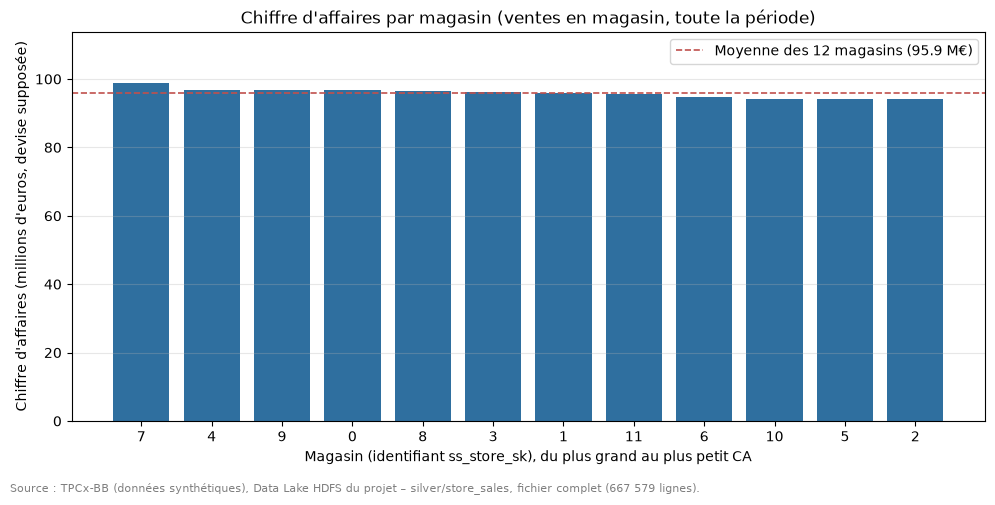

In [16]:
pdf_graph = pdf_magasins.sort_values("chiffre_affaires", ascending=False)
moyenne_ca = pdf_graph["chiffre_affaires"].mean() / 1e6

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(pdf_graph["magasin"].astype(str), pdf_graph["chiffre_affaires"] / 1e6, color="#2f6f9f")
ax.axhline(moyenne_ca, color="#c0504d", linestyle="--", linewidth=1.2,
           label=f"Moyenne des 12 magasins ({moyenne_ca:.1f} M€)")

ax.set_title("Chiffre d'affaires par magasin (ventes en magasin, toute la période)")
ax.set_xlabel("Magasin (identifiant ss_store_sk), du plus grand au plus petit CA")
ax.set_ylabel("Chiffre d'affaires (millions d'euros, devise supposée)")
ax.set_ylim(0, pdf_graph["chiffre_affaires"].max() / 1e6 * 1.15)
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper right")
fig.text(0.01, 0.005, SOURCE_DONNEES + " – silver/store_sales, fichier complet (667 579 lignes).",
         fontsize=8, color="gray")

fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(DOSSIER_GRAPHIQUES / "ca_par_magasin.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation**

- **Ce que montre le graphique** : le chiffre d'affaires de chacun des 12 magasins, sur toute la période, du plus grand au plus petit.
- **Résultat principal** : les magasins sont **très proches**. Leur CA va de 94,0 M€ (magasin 2) à 99,0 M€ (magasin 7), soit seulement 5,2 % d'écart entre le premier et le dernier. Chaque magasin fait entre 8,2 % et 8,6 % du CA.
- **Autres KPI par magasin** (tableau ci-dessus) : le panier moyen va de 12 723 à 13 027 € par ticket et le taux de remise de 49,8 % à 50,4 %. Là aussi, presque aucune différence.
- **Interprétation possible** : le magasin 7 est premier surtout parce qu'il a **plus de tickets** (7 645, le plus haut), pas parce que ses clients dépensent plus (son panier moyen, 12 943 €, est dans la moyenne). Des magasins aussi semblables viennent sûrement de la façon dont TPCx-BB génère les données.
- **Limites** : on ne connaît ni la taille, ni la surface, ni la ville des magasins (`store` n'est pas dans notre Silver). Un CA plus élevé ne veut donc pas dire qu'un magasin est plus performant.

## 9. Interprétation et limites

- **Données synthétiques** : TPCx-BB génère les données au hasard. Les résultats servent à travailler la démarche, pas à décrire une vraie enseigne.
- **Ventes en magasin seulement** : `web_sales` n'est pas dans notre Silver. Les KPI ne couvrent donc pas le web, et la question « magasins ou web ? » (P1) n'est pas traitée.
- **Pas de dates** : `ss_sold_date_sk` est un numéro de jour. Sans `date_dim`, on ne peut pas calculer l'évolution du CA (KPI-06) ni faire de courbe par mois.
- **Pas de marge** : 74 % des lignes ont une marge négative (TP3). La marge n'est pas fiable, je ne l'ai pas calculée.
- **Retours non déduits** : `store_returns` n'est pas traité, le CA est donc un CA « avant retours ».
- **Devise supposée** : la devise n'est pas indiquée, on suppose l'euro (comme au Jour 1).
- **Panier moyen très élevé** (12 913 € par ticket) : un ticket a en moyenne 7,5 lignes et chaque ligne environ 50 articles. Ce n'est pas réaliste, mais le calcul est juste pour ces données.
- **Taux de remise d'environ 50 %** partout : très élevé, il vient lui aussi de la génération des données.

## 10. Conclusion et recommandations

**Constat 1 – Deux catégories font presque les trois quarts du CA**

- *Résultat observé* : `Music` et `Books` font 71,9 % du CA des magasins.
- *Interprétation possible* : ce sont les catégories qui ont le plus de produits au catalogue ; leur CA par produit est plutôt plus faible que celui des petites catégories.
- *Limite* : données synthétiques, magasins seulement, sans période.
- *Recommandation* : pour comparer les catégories, regarder aussi le **CA par produit**, et pas seulement le CA total, avant de décider quelles catégories mettre en avant.

**Constat 2 – Les 12 magasins ont des résultats presque identiques**

- *Résultat observé* : 5,2 % d'écart de CA entre le premier et le dernier magasin ; panier moyen et taux de remise presque identiques.
- *Interprétation possible* : aucun magasin ne se détache vraiment. Le premier (magasin 7) a surtout plus de tickets.
- *Limite* : sans la taille ni la localisation des magasins, on ne peut pas juger leur performance.
- *Recommandation* : ajouter la table `store` dans le Silver (nom, surface, ville) pour comparer des magasins comparables, par exemple le CA par m².

**Pour la suite** : charger `date_dim` pour pouvoir suivre le CA par mois (KPI-06, question P1 Indispensable), et `web_sales` pour comparer les magasins et le web.

In [17]:
print("Fichiers produits :")
for fichier in sorted(list(DOSSIER_SORTIES.glob("*.csv")) + list(DOSSIER_GRAPHIQUES.glob("*.png"))):
    print("  ", fichier, f"({fichier.stat().st_size} octets)")
spark.stop()

Fichiers produits :
   ../outputs/hdfs/ca_par_categorie.csv (629 octets)
   ../outputs/hdfs/kpi.csv (635 octets)
   ../outputs/hdfs/kpi_par_magasin.csv (660 octets)
   ../outputs/hdfs/statistiques.csv (473 octets)
   ../visualizations/hdfs/ca_par_categorie.png (85509 octets)
   ../visualizations/hdfs/ca_par_magasin.png (69310 octets)
